CQR

Обучение модели для нижнего квантиля (0.05)...
Обучение модели для верхнего квантиля (0.95)...
h = 0.0 | Plug-in Coverage = 0.857 | Mean X_test = 0.017 | Fraction X_test > 0 = 0.512
h = 0.5 | Plug-in Coverage = 0.880 | Mean X_test = 0.552 | Fraction X_test > 0 = 0.719
h = 1.0 | Plug-in Coverage = 0.874 | Mean X_test = 1.033 | Fraction X_test > 0 = 0.858


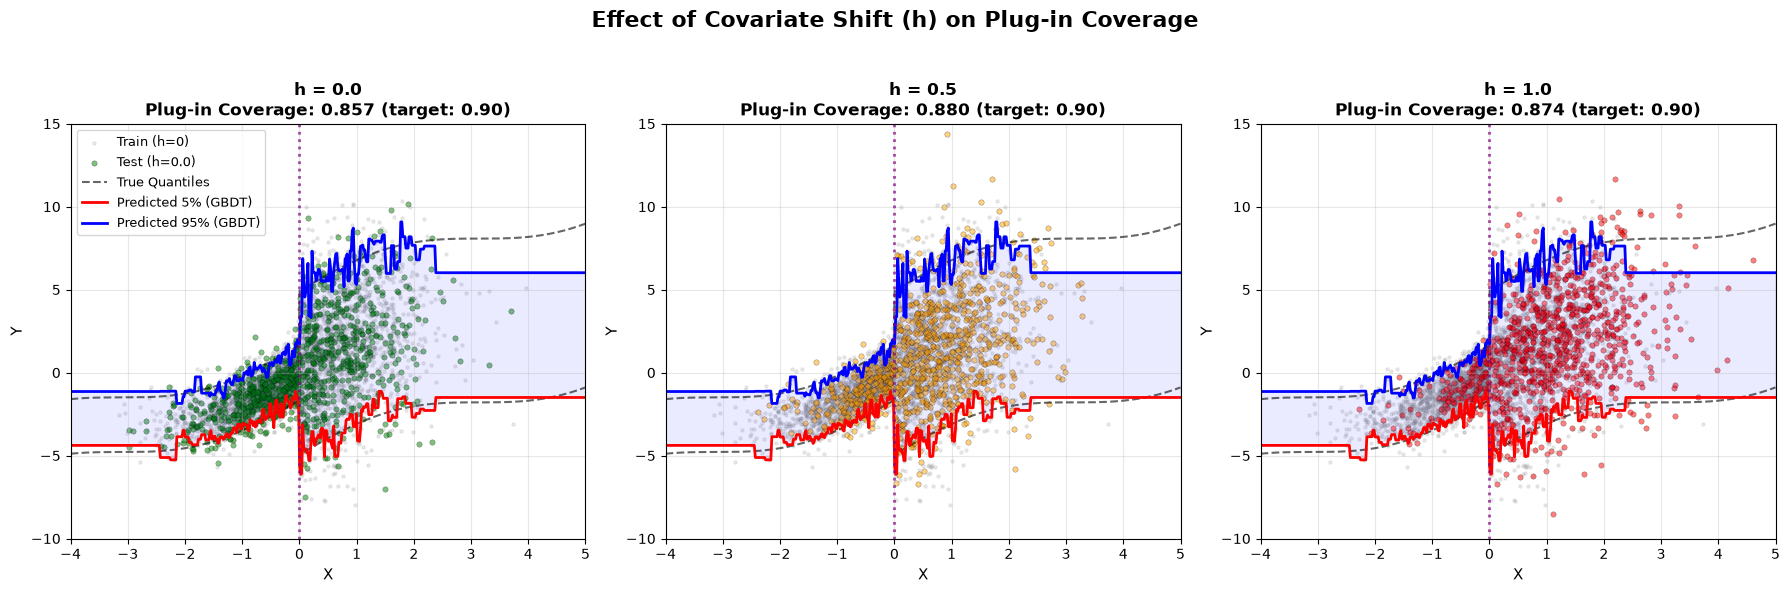


СВОДНАЯ ТАБЛИЦА: Влияние ковариатного сдвига на Plug-in покрытие
h     | Plug-in Coverage   | Доля X>0 в тесте   | Интерпретация
----------------------------------------------------------------------
0.0   | 0.857              | 0.512              | ⚠ Лёгкое недопокрытие
0.5   | 0.880              | 0.719              | ✓ Валидно
1.0   | 0.874              | 0.858              | ⚠ Лёгкое недопокрытие


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import norm
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Генерация данных
# ==========================================
def generate_data(n, h_shift=0.0, seed=42):
    np.random.seed(seed)
    # X ~ N(h, 1)
    X = np.random.normal(loc=h_shift, scale=1.0, size=n)
    
    # sigma(X) = 1 при X <= 0, и 3 при X > 0
    sigma = np.where(X <= 0, 1.0, 3.0)
    eps = np.random.normal(0, 1, size=n)
    
    # Y = X + sin(X) + sigma(X) * eps
    Y = X + np.sin(X) + sigma * eps
    return X.reshape(-1, 1), Y

# ==========================================
# 2. Разбиение данных (Train и Calibration остаются с h=0)
# ==========================================
n_train = 3000
n_cal = 2000
n_test = 1000  # размер тестовой выборки для каждого h

# Исходное распределение (h=0) - на нём мы обучаемся и калибруемся
X_train, Y_train = generate_data(n_train, h_shift=0.0, seed=1)
X_cal, Y_cal = generate_data(n_cal, h_shift=0.0, seed=2)

# ==========================================
# 3. Обучение базовых моделей (Quantile GBDT)
# ==========================================
print("Обучение модели для нижнего квантиля (0.05)...")
q_lo_model = HistGradientBoostingRegressor(
    loss='quantile', 
    quantile=0.05, 
    max_iter=300, 
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)
q_lo_model.fit(X_train, Y_train)

print("Обучение модели для верхнего квантиля (0.95)...")
q_hi_model = HistGradientBoostingRegressor(
    loss='quantile', 
    quantile=0.95, 
    max_iter=300, 
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)
q_hi_model.fit(X_train, Y_train)

# ==========================================
# 4. Сетка для графиков и истинные квантили
# ==========================================
# Объединяем диапазон всех возможных X (с учётом сдвига до h=1)
X_grid = np.linspace(-4, 5, 500).reshape(-1, 1)

pred_lo = q_lo_model.predict(X_grid)
pred_hi = q_hi_model.predict(X_grid)

X_grid_flat = X_grid.flatten()
sigma_grid = np.where(X_grid_flat <= 0, 1.0, 3.0)
true_lo = X_grid_flat + np.sin(X_grid_flat) + sigma_grid * norm.ppf(0.05)
true_hi = X_grid_flat + np.sin(X_grid_flat) + sigma_grid * norm.ppf(0.95)

# ==========================================
# 5. Функция для расчёта Plug-in покрытия
# ==========================================
def compute_plug_in_coverage(X_test, Y_test, q_lo, q_hi):
    """Считаем, какое покрытие даёт модель 'как есть' без конформной калибровки"""
    pred_lo = q_lo.predict(X_test)
    pred_hi = q_hi.predict(X_test)
    is_covered = (Y_test >= pred_lo) & (Y_test <= pred_hi)
    return np.mean(is_covered)

# ==========================================
# 6. Визуализация для трёх случаев h
# ==========================================
h_values = [0.0, 0.5, 1.0]
colors_test = ['green', 'orange', 'red']  # цвета для тестовых точек

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Effect of Covariate Shift (h) on Plug-in Coverage', fontsize=16, fontweight='bold')

for idx, h in enumerate(h_values):
    ax = axes[idx]
    
    # Генерируем тестовые данные для текущего h
    X_test, Y_test = generate_data(n_test, h_shift=h, seed=3 + idx)
    
    # Считаем Plug-in покрытие на тесте
    plug_in_cov = compute_plug_in_coverage(X_test, Y_test, q_lo_model, q_hi_model)
    
    # --- Рисуем на subplot ---
    # 1. Train данные (серые точки, фон)
    ax.scatter(X_train, Y_train, s=5, alpha=0.15, color='gray', label='Train (h=0)')
    
    # 2. Тестовые данные текущего h (цветные точки, поверх)
    ax.scatter(X_test, Y_test, s=15, alpha=0.5, color=colors_test[idx], 
               label=f'Test (h={h})', edgecolor='black', linewidth=0.3)
    
    # 3. Истинные квантили (чёрный пунктир)
    ax.plot(X_grid, true_lo, 'k--', linewidth=1.5, alpha=0.6)
    ax.plot(X_grid, true_hi, 'k--', linewidth=1.5, alpha=0.6, label='True Quantiles')
    
    # 4. Предсказанные квантили (красная/синяя линии)
    ax.plot(X_grid, pred_lo, 'r-', linewidth=2, label='Predicted 5% (GBDT)')
    ax.plot(X_grid, pred_hi, 'b-', linewidth=2, label='Predicted 95% (GBDT)')
    
    # 5. Заштрихованная область между предсказанными квантилями
    ax.fill_between(X_grid.flatten(), pred_lo, pred_hi, color='blue', alpha=0.08)
    
    # 6. Вертикальная линия - граница изменения дисперсии
    ax.axvline(0, color='purple', linestyle=':', linewidth=2, alpha=0.7)
    
    # 7. Заголовок с Plug-in покрытием
    ax.set_title(f'h = {h}\nPlug-in Coverage: {plug_in_cov:.3f} (target: 0.90)', 
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('X', fontsize=11)
    ax.set_ylabel('Y', fontsize=11)
    ax.set_xlim(-4, 5)
    ax.set_ylim(-10, 15)
    ax.grid(True, alpha=0.3)
    
    # Легенда только на первом subplot (чтобы не загромождать)
    if idx == 0:
        ax.legend(loc='upper left', fontsize=9)
    
    print(f"h = {h:.1f} | Plug-in Coverage = {plug_in_cov:.3f} | "
          f"Mean X_test = {X_test.mean():.3f} | "
          f"Fraction X_test > 0 = {(X_test > 0).mean():.3f}")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ==========================================
# 7. Сводная таблица результатов
# ==========================================
print("\n" + "="*70)
print("СВОДНАЯ ТАБЛИЦА: Влияние ковариатного сдвига на Plug-in покрытие")
print("="*70)
print(f"{'h':<5} | {'Plug-in Coverage':<18} | {'Доля X>0 в тесте':<18} | {'Интерпретация'}")
print("-"*70)
for h in h_values:
    X_test, Y_test = generate_data(n_test, h_shift=h, seed=3 + h_values.index(h))
    cov = compute_plug_in_coverage(X_test, Y_test, q_lo_model, q_hi_model)
    frac_pos = (X_test > 0).mean()
    
    if cov >= 0.88:
        interp = "✓ Валидно"
    elif cov >= 0.80:
        interp = "⚠ Лёгкое недопокрытие"
    else:
        interp = "✗ Сильное недопокрытие"
    
    print(f"{h:<5.1f} | {cov:<18.3f} | {frac_pos:<18.3f} | {interp}")
print("="*70)

Вопрос: почему покрытие увеличивается, если у нас происходит сдвиг (модель не должна подстраиваться под изменение данных)

- обычная CQR
- взвешенная CQR с истинными весами
- взвешенная CQR с весами, оценёнными по данным

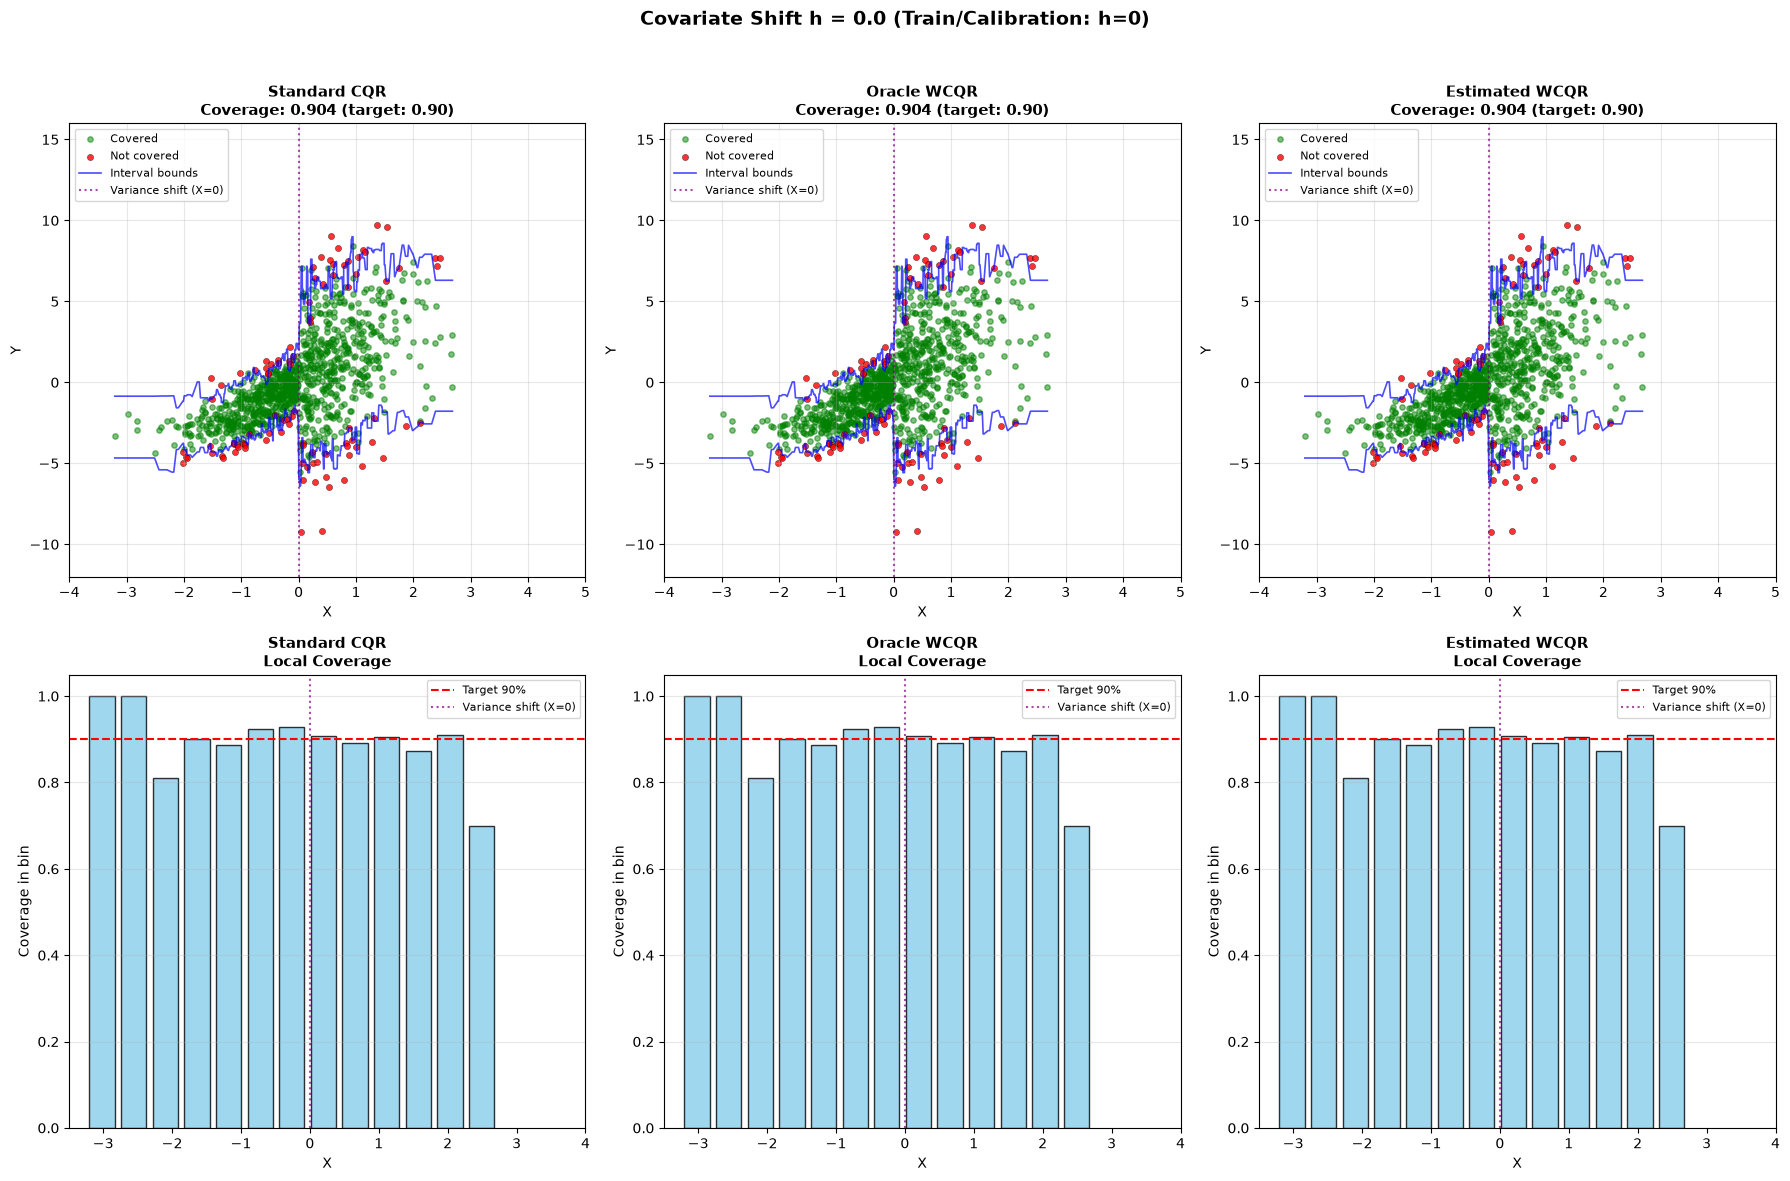

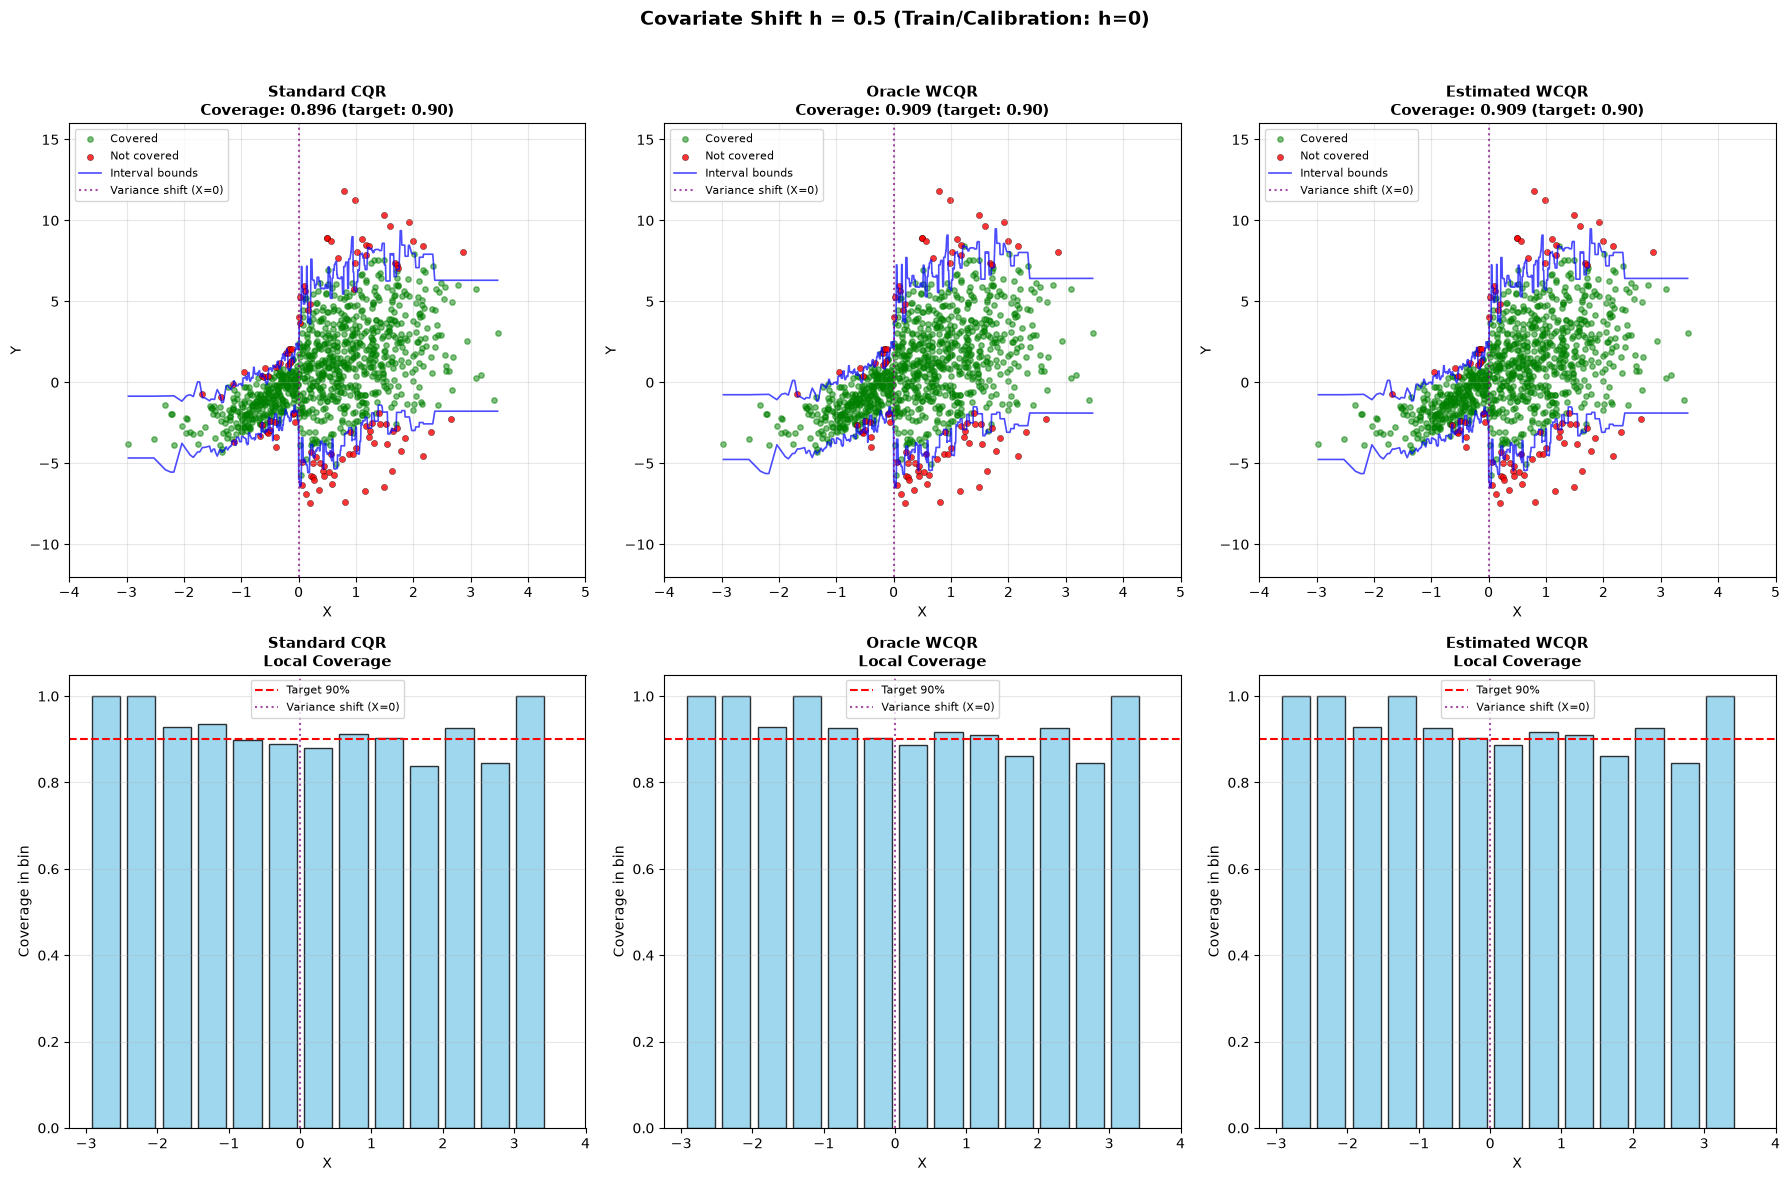

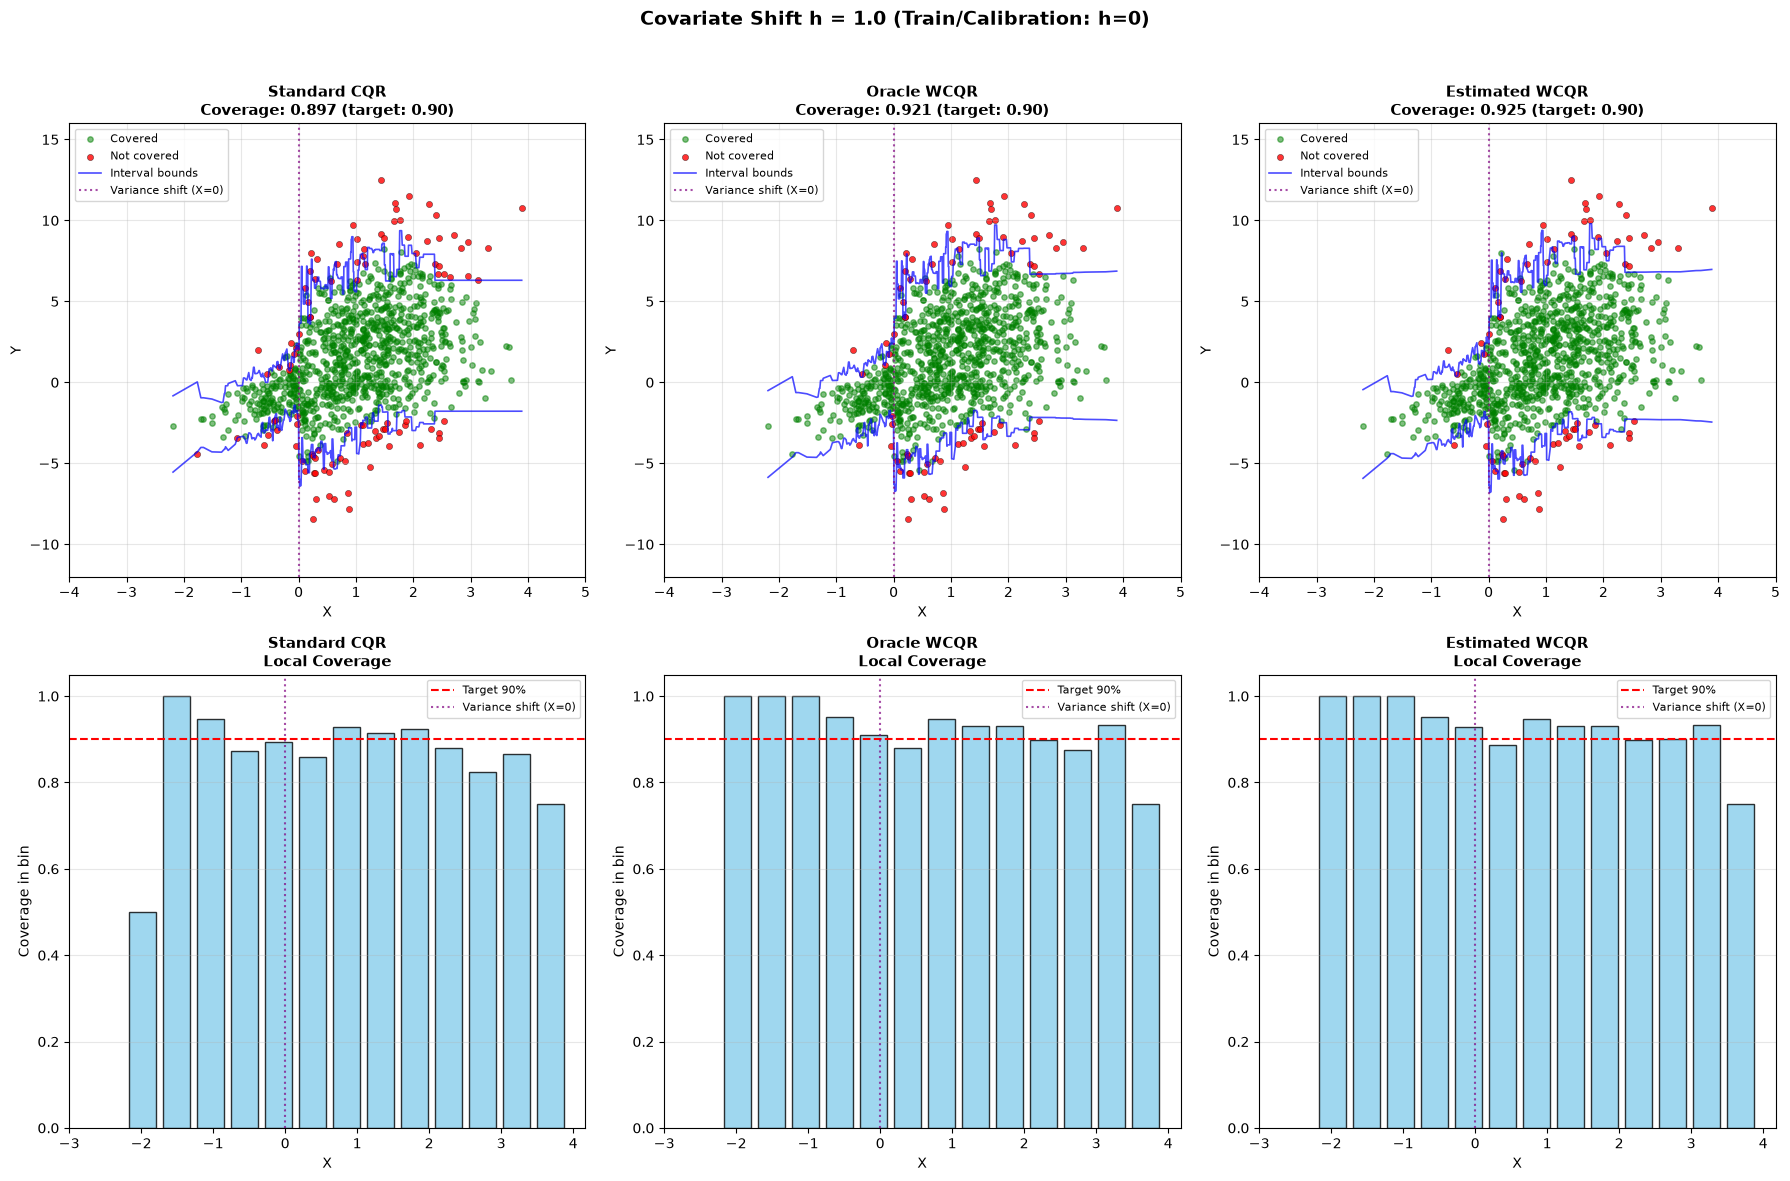

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from scipy.stats import norm
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Генерация данных
# ==========================================
def generate_data(n, h_shift=0.0, seed=42):
    np.random.seed(seed)
    X = np.random.normal(loc=h_shift, scale=1.0, size=n)
    sigma = np.where(X <= 0, 1.0, 3.0)
    eps = np.random.normal(0, 1, size=n)
    Y = X + np.sin(X) + sigma * eps
    return X.reshape(-1, 1), Y

# ==========================================
# 2. Обучение квантильных моделей
# ==========================================
def train_quantile_models(X_train, Y_train, alpha=0.1):
    q_lo = HistGradientBoostingRegressor(
        loss='quantile', quantile=alpha/2,
        max_iter=300, learning_rate=0.05, max_depth=5, random_state=42
    )
    q_hi = HistGradientBoostingRegressor(
        loss='quantile', quantile=1 - alpha/2,
        max_iter=300, learning_rate=0.05, max_depth=5, random_state=42
    )
    q_lo.fit(X_train, Y_train)
    q_hi.fit(X_train, Y_train)
    return q_lo, q_hi

# ==========================================
# 3. Истинные квантили (для отрисовки)
# ==========================================
def get_true_quantiles(X_grid):
    X_flat = X_grid.flatten()
    sigma = np.where(X_flat <= 0, 1.0, 3.0)
    true_lo = X_flat + np.sin(X_flat) + sigma * norm.ppf(0.05)
    true_hi = X_flat + np.sin(X_flat) + sigma * norm.ppf(0.95)
    return true_lo, true_hi

# ==========================================
# 4. Веса
# ==========================================
def get_oracle_weights(X, h):
    return np.exp(h * X.flatten() - (h**2) / 2)

def get_estimated_weights(X_cal, X_test_unlabeled, clip_eps=1e-5):
    X_mix = np.vstack([X_cal, X_test_unlabeled])
    y_mix = np.hstack([np.zeros(len(X_cal)), np.ones(len(X_test_unlabeled))])
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_mix, y_mix)
    p_test = np.clip(clf.predict_proba(X_mix)[:, 1], clip_eps, 1 - clip_eps)
    w_mix = p_test / (1 - p_test)
    return w_mix[:len(X_cal)], w_mix[len(X_cal):]

# ==========================================
# 5. Конформные квантили
# ==========================================
def get_standard_cqr_quantile(E_cal, alpha=0.1):
    q_level = min(1.0, (1 - alpha) * (1 + 1 / len(E_cal)))
    return np.quantile(E_cal, q_level)

def get_weighted_cqr_quantile(E_cal, w_cal, w_test_point, alpha=0.1):
    sum_w_cal = np.sum(w_cal)
    p_cal = w_cal / (sum_w_cal + w_test_point)
    sorted_idx = np.argsort(E_cal)
    sorted_E = E_cal[sorted_idx]
    sorted_p = p_cal[sorted_idx]
    cum_p = np.cumsum(sorted_p)
    idx = np.searchsorted(cum_p, 1 - alpha)
    if idx >= len(sorted_E):
        return np.inf
    return sorted_E[idx]

# ==========================================
# 6. Построение интервалов
# ==========================================
def build_intervals(X_test, Y_test, q_lo, q_hi, E_cal, w_cal, w_test, method='standard', alpha=0.1):
    preds_lo = q_lo.predict(X_test)
    preds_hi = q_hi.predict(X_test)
    
    lower_bounds = np.zeros(len(X_test))
    upper_bounds = np.zeros(len(X_test))
    is_covered = np.zeros(len(X_test), dtype=bool)
    
    for i in range(len(X_test)):
        if method == 'standard':
            Q = get_standard_cqr_quantile(E_cal, alpha)
        else:
            Q = get_weighted_cqr_quantile(E_cal, w_cal, w_test[i], alpha)
        
        lower_bounds[i] = preds_lo[i] - Q
        upper_bounds[i] = preds_hi[i] + Q
        is_covered[i] = (lower_bounds[i] <= Y_test[i]) & (Y_test[i] <= upper_bounds[i])
    
    return is_covered, lower_bounds, upper_bounds

# ==========================================
# 7. Визуализация: точки + интервалы
# ==========================================
def plot_intervals(ax, X_test, Y_test, is_covered, lower_bounds, upper_bounds, 
                   method_name, h, alpha=0.1):
    sort_idx = np.argsort(X_test.flatten())
    X_s = X_test[sort_idx].flatten()
    Y_s = Y_test[sort_idx].flatten()
    cov_s = is_covered[sort_idx]
    low_s = lower_bounds[sort_idx]
    up_s = upper_bounds[sort_idx]
    
    ax.scatter(X_s[cov_s], Y_s[cov_s], color='green', s=15, alpha=0.5, label='Covered')
    ax.scatter(X_s[~cov_s], Y_s[~cov_s], color='red', s=20, alpha=0.8, 
               edgecolor='black', linewidth=0.3, label='Not covered')
    
    ax.plot(X_s, low_s, color='blue', linewidth=1.2, alpha=0.7, label='Interval bounds')
    ax.plot(X_s, up_s, color='blue', linewidth=1.2, alpha=0.7)
    ax.axvline(0, color='purple', linestyle=':', linewidth=1.5, alpha=0.7, 
               label='Variance shift (X=0)')
    
    coverage_rate = np.mean(is_covered)
    ax.set_title(f'{method_name}\nCoverage: {coverage_rate:.3f} (target: 0.90)', 
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('X', fontsize=10)
    ax.set_ylabel('Y', fontsize=10)
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-4, 5)
    ax.set_ylim(-12, 16)

# ==========================================
# 8. Визуализация: локальное покрытие
# ==========================================
def plot_local_coverage(ax, X_test, is_covered, method_name, h, alpha=0.1):
    X_s = X_test.flatten()
    cov_s = is_covered
    
    # Разбиваем на бины
    n_bins = 15
    bins = np.linspace(X_s.min() - 0.5, X_s.max() + 0.5, n_bins + 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    local_coverage = []
    bin_counts = []
    
    for i in range(n_bins):
        mask = (X_s >= bins[i]) & (X_s < bins[i+1])
        count = np.sum(mask)
        bin_counts.append(count)
        if count > 0:
            local_coverage.append(np.mean(cov_s[mask]))
        else:
            local_coverage.append(np.nan)
    
    # Строим столбчатую диаграмму
    ax.bar(bin_centers, local_coverage, width=(bins[1]-bins[0])*0.8, 
           color='skyblue', edgecolor='black', alpha=0.8)
    ax.axhline(0.9, color='red', linestyle='--', linewidth=1.5, label='Target 90%')
    ax.axvline(0, color='purple', linestyle=':', linewidth=1.5, alpha=0.7, 
               label='Variance shift (X=0)')
    
    ax.set_title(f'{method_name}\nLocal Coverage', fontsize=11, fontweight='bold')
    ax.set_xlabel('X', fontsize=10)
    ax.set_ylabel('Coverage in bin', fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.set_xticks(np.arange(-3, 5, 1))
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')

# ==========================================
# 9. Основной запуск
# ==========================================
def run_full_visualization():
    np.random.seed(42)
    n_train, n_cal, n_test = 3000, 2000, 1000
    alpha = 0.1
    
    # Обучаем на h=0
    X_train, Y_train = generate_data(n_train, h_shift=0.0, seed=1)
    X_cal, Y_cal = generate_data(n_cal, h_shift=0.0, seed=2)
    q_lo, q_hi = train_quantile_models(X_train, Y_train, alpha)
    
    # Считаем E_cal
    preds_lo_cal = q_lo.predict(X_cal)
    preds_hi_cal = q_hi.predict(X_cal)
    E_cal = np.maximum(preds_lo_cal - Y_cal, Y_cal - preds_hi_cal)
    
    h_values = [0.0, 0.5, 1.0]
    methods = [
        ('Standard CQR', None, None, 'standard'),
        ('Oracle WCQR', 'oracle', None, 'weighted'),
        ('Estimated WCQR', 'estimated', None, 'weighted')
    ]
    
    for h in h_values:
        X_test, Y_test = generate_data(n_test, h_shift=h, seed=10 + int(h*10))
        
        # Веса
        w_cal_oracle = get_oracle_weights(X_cal, h)
        w_test_oracle = get_oracle_weights(X_test, h)
        w_cal_est, w_test_est = get_estimated_weights(X_cal, X_test)
        
        # Создаём фигуру: 2 строки × 3 столбца
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle(f'Covariate Shift h = {h} (Train/Calibration: h=0)', 
                     fontsize=14, fontweight='bold')
        
        for col, (method_name, w_type, _, method_key) in enumerate(methods):
            if w_type is None:
                w_cal, w_test = None, None
            elif w_type == 'oracle':
                w_cal, w_test = w_cal_oracle, w_test_oracle
            else:
                w_cal, w_test = w_cal_est, w_test_est
            
            is_cov, low_b, up_b = build_intervals(
                X_test, Y_test, q_lo, q_hi, E_cal, w_cal, w_test,
                method=method_key, alpha=alpha
            )
            
            # Верхняя строка: точки + интервалы
            plot_intervals(
                axes[0, col], X_test, Y_test, is_cov, low_b, up_b,
                method_name, h, alpha
            )
            
            # Нижняя строка: локальное покрытие
            plot_local_coverage(
                axes[1, col], X_test, is_cov, method_name, h, alpha
            )
        
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

# Запуск
run_full_visualization()

При увеличении h видно увеличение покрытия при применении более точных моделей (может быть стоит провести эксперименты с большим h)

Меняем размер валидационной выборки

In [3]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Генерация данных и базовые функции (без изменений)
# ==========================================
def generate_data(n, h_shift=0.0, seed=42):
    np.random.seed(seed)
    X = np.random.normal(loc=h_shift, scale=1.0, size=n).reshape(-1, 1)
    sigma = np.where(X <= 0, 1.0, 3.0)
    eps = np.random.normal(0, 1, size=n)
    Y = X.flatten() + np.sin(X.flatten()) + sigma.flatten() * eps
    return X, Y

def train_quantile_models(X_train, Y_train, alpha=0.1):
    q_lo = HistGradientBoostingRegressor(loss='quantile', quantile=alpha/2, max_iter=300, learning_rate=0.05, max_depth=5, random_state=42)
    q_hi = HistGradientBoostingRegressor(loss='quantile', quantile=1 - alpha/2, max_iter=300, learning_rate=0.05, max_depth=5, random_state=42)
    q_lo.fit(X_train, Y_train)
    q_hi.fit(X_train, Y_train)
    return q_lo, q_hi

def get_oracle_weights(X, h):
    return np.exp(h * X.flatten() - (h**2) / 2)

def get_estimated_weights(X_cal, X_test_unlabeled, clip_eps=1e-5):
    X_mix = np.vstack([X_cal, X_test_unlabeled])
    y_mix = np.hstack([np.zeros(len(X_cal)), np.ones(len(X_test_unlabeled))])
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_mix, y_mix)
    p_test = np.clip(clf.predict_proba(X_mix)[:, 1], clip_eps, 1 - clip_eps)
    w_mix = p_test / (1 - p_test)
    return w_mix[:len(X_cal)], w_mix[len(X_cal):]

def get_standard_cqr_quantile(E_cal, alpha=0.1):
    q_level = min(1.0, (1 - alpha) * (1 + 1 / len(E_cal)))
    return np.quantile(E_cal, q_level)

def get_weighted_cqr_quantile_STRICT(E_cal, w_cal, w_test_point, alpha=0.1):
    sum_w_cal = np.sum(w_cal)
    p_cal = w_cal / (sum_w_cal + w_test_point)
    sorted_idx = np.argsort(E_cal)
    sorted_E = E_cal[sorted_idx]
    sorted_p = p_cal[sorted_idx]
    cum_p = np.cumsum(sorted_p)
    idx = np.searchsorted(cum_p, 1 - alpha)
    if idx >= len(sorted_E):
        return np.inf
    return sorted_E[idx]

def compute_ess(w):
    return (np.sum(w))**2 / np.sum(w**2)

def evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal, w_test, method='standard', alpha=0.1):
    preds_lo = q_lo.predict(X_test)
    preds_hi = q_hi.predict(X_test)
    
    covers = []
    lengths = []
    n_inf = 0
    
    for i in range(len(X_test)):
        if method == 'standard':
            Q = get_standard_cqr_quantile(E_cal, alpha)
        else:
            Q = get_weighted_cqr_quantile_STRICT(E_cal, w_cal, w_test[i], alpha)
            
        lower = preds_lo[i] - Q
        upper = preds_hi[i] + Q
        
        is_covered = 1 if (lower <= Y_test[i] <= upper) else 0
        covers.append(is_covered)
        
        if np.isinf(Q):
            lengths.append(np.inf)
            n_inf += 1
        else:
            lengths.append(upper - lower)
            
    avg_length_finite = np.mean([L for L in lengths if not np.isinf(L)]) if n_inf < len(X_test) else np.nan
    return np.mean(covers), avg_length_finite, n_inf / len(X_test)

# ==========================================
# 2. Основной цикл: Варьирование n_cal
# ==========================================
def run_n_cal_experiment():
    np.random.seed(42)
    n_train = 3000      # Фиксируем большую обучающую выборку
    n_test = 2000
    h_test = 1.0        # Фиксируем сдвиг
    alpha = 0.1
    
    # Варьируем размер калибровочной выборки
    n_cal_values = [100, 200, 500, 1000, 2000, 5000]
    
    results = []
    
    # Фиксируем train и test
    X_train, Y_train = generate_data(n_train, h_shift=0.0, seed=1)
    q_lo, q_hi = train_quantile_models(X_train, Y_train, alpha)
    
    X_test, Y_test = generate_data(n_test, h_shift=h_test, seed=10 + int(h_test*10))
    
    # Веса для теста фиксируем (они зависят только от X_test)
    w_test_oracle = get_oracle_weights(X_test, h_test)
    
    print(f"{'n_cal':<6} | {'Метод':<15} | {'Покрытие':<9} | {'Ср. длина':<10} | {'Доля inf':<8} | {'ESS':<8}")
    print("-" * 70)
    
    for n_cal in n_cal_values:
        # Генерируем калибровку для текущего n_cal
        X_cal, Y_cal = generate_data(n_cal, h_shift=0.0, seed=2)
        
        # Считаем E_cal
        preds_lo_cal = q_lo.predict(X_cal)
        preds_hi_cal = q_hi.predict(X_cal)
        E_cal = np.maximum(preds_lo_cal - Y_cal, Y_cal - preds_hi_cal)
        
        # Веса для калибровки
        w_cal_oracle = get_oracle_weights(X_cal, h_test)
        w_cal_est, w_test_est = get_estimated_weights(X_cal, X_test)
        
        # ESS
        ess_oracle = compute_ess(w_cal_oracle)
        ess_est = compute_ess(w_cal_est)
        
        # 1. Standard CQR
        cov_std, len_std, inf_std = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, None, None, 'standard', alpha)
        
        # 2. Oracle WCQR
        cov_oracle, len_oracle, inf_oracle = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal_oracle, w_test_oracle, 'weighted', alpha)
        
        # 3. Estimated WCQR
        cov_est, len_est, inf_est = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal_est, w_test_est, 'weighted', alpha)
        
        for name, cov, length, inf_frac, ess in [
            ('Standard', cov_std, len_std, inf_std, np.nan),
            ('Oracle', cov_oracle, len_oracle, inf_oracle, ess_oracle),
            ('Estimated', cov_est, len_est, inf_est, ess_est)
        ]:
            results.append({
                'n_cal': n_cal,
                'h_test': h_test,
                'n_train': n_train,
                'Метод': name + ' CQR',
                'Покрытие': cov,
                'Ср. длина интервала': length,
                'Доля inf интервалов': inf_frac,
                'ESS калибровки': ess
            })
            ess_str = f"{ess:.0f}" if not np.isnan(ess) else "-"
            print(f"{n_cal:<6} | {name:<15} | {cov:<9.3f} | {length:<10.2f} | {inf_frac:<8.3f} | {ess_str:<8}")
        print("-" * 70)
        
    return pd.DataFrame(results)

# Запуск
df_n_cal = run_n_cal_experiment()

# ==========================================
# 3. Сохранение и форматирование
# ==========================================
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

df_formatted = df_n_cal.copy()
df_formatted['Покрытие'] = df_formatted['Покрытие'].map('{:.3f}'.format)
df_formatted['Ср. длина интервала'] = df_formatted['Ср. длина интервала'].map(lambda x: f"{x:.2f}" if not np.isnan(x) else "NaN")
df_formatted['Доля inf интервалов'] = df_formatted['Доля inf интервалов'].map('{:.3f}'.format)
df_formatted['ESS калибровки'] = df_formatted['ESS калибровки'].map(lambda x: f"{x:.0f}" if not np.isnan(x) else "-")

# Сохранение в Excel
excel_filename = "cqr_n_cal_experiment.xlsx"
with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    df_n_cal.to_excel(writer, sheet_name='Detailed_Results', index=False)
    df_formatted.to_excel(writer, sheet_name='Formatted_Table', index=False)
print(f"\n✅ Данные сохранены в {excel_filename}")

n_cal  | Метод           | Покрытие  | Ср. длина  | Доля inf | ESS     
----------------------------------------------------------------------
100    | Standard        | 0.889     | 8.97       | 0.000    | -       
100    | Oracle          | 0.976     | 12.14      | 0.035    | 44      
100    | Estimated       | 0.979     | 12.34      | 0.042    | 40      
----------------------------------------------------------------------
200    | Standard        | 0.888     | 8.93       | 0.000    | -       
200    | Oracle          | 0.963     | 11.22      | 0.002    | 29      
200    | Estimated       | 0.958     | 10.94      | 0.001    | 34      
----------------------------------------------------------------------
500    | Standard        | 0.890     | 8.99       | 0.000    | -       
500    | Oracle          | 0.880     | 8.81       | 0.000    | 100     
500    | Estimated       | 0.881     | 8.81       | 0.000    | 101     
-------------------------------------------------------------------

При увеличении выборки должна увеличиваться точность (но она падает, когда train больше test, вопрос, насколько это нормально?). Средняя длина интервала ведет себя непредсказуемо, сложно выявить какую-то зависимость.

Меняем размер тренировочной выборки

In [4]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Генерация данных и базовые функции (без изменений)
# ==========================================
def generate_data(n, h_shift=0.0, seed=42):
    np.random.seed(seed)
    X = np.random.normal(loc=h_shift, scale=1.0, size=n).reshape(-1, 1)
    sigma = np.where(X <= 0, 1.0, 3.0)
    eps = np.random.normal(0, 1, size=n)
    Y = X.flatten() + np.sin(X.flatten()) + sigma.flatten() * eps
    return X, Y

def train_quantile_models(X_train, Y_train, alpha=0.1):
    # Для очень маленьких выборок уменьшаем max_iter, чтобы не было предупреждений о сходимости
    max_it = 100 if len(X_train) < 500 else 300
    q_lo = HistGradientBoostingRegressor(loss='quantile', quantile=alpha/2, max_iter=max_it, learning_rate=0.05, max_depth=5, random_state=42)
    q_hi = HistGradientBoostingRegressor(loss='quantile', quantile=1 - alpha/2, max_iter=max_it, learning_rate=0.05, max_depth=5, random_state=42)
    q_lo.fit(X_train, Y_train)
    q_hi.fit(X_train, Y_train)
    return q_lo, q_hi

def get_oracle_weights(X, h):
    return np.exp(h * X.flatten() - (h**2) / 2)

def get_estimated_weights(X_cal, X_test_unlabeled, clip_eps=1e-5):
    X_mix = np.vstack([X_cal, X_test_unlabeled])
    y_mix = np.hstack([np.zeros(len(X_cal)), np.ones(len(X_test_unlabeled))])
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_mix, y_mix)
    p_test = np.clip(clf.predict_proba(X_mix)[:, 1], clip_eps, 1 - clip_eps)
    w_mix = p_test / (1 - p_test)
    return w_mix[:len(X_cal)], w_mix[len(X_cal):]

def get_standard_cqr_quantile(E_cal, alpha=0.1):
    q_level = min(1.0, (1 - alpha) * (1 + 1 / len(E_cal)))
    return np.quantile(E_cal, q_level)

def get_weighted_cqr_quantile_STRICT(E_cal, w_cal, w_test_point, alpha=0.1):
    sum_w_cal = np.sum(w_cal)
    p_cal = w_cal / (sum_w_cal + w_test_point)
    sorted_idx = np.argsort(E_cal)
    sorted_E = E_cal[sorted_idx]
    sorted_p = p_cal[sorted_idx]
    cum_p = np.cumsum(sorted_p)
    idx = np.searchsorted(cum_p, 1 - alpha)
    if idx >= len(sorted_E):
        return np.inf
    return sorted_E[idx]

def compute_ess(w):
    return (np.sum(w))**2 / np.sum(w**2)

def evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal, w_test, method='standard', alpha=0.1):
    preds_lo = q_lo.predict(X_test)
    preds_hi = q_hi.predict(X_test)
    
    covers = []
    lengths = []
    n_inf = 0
    
    for i in range(len(X_test)):
        if method == 'standard':
            Q = get_standard_cqr_quantile(E_cal, alpha)
        else:
            Q = get_weighted_cqr_quantile_STRICT(E_cal, w_cal, w_test[i], alpha)
            
        lower = preds_lo[i] - Q
        upper = preds_hi[i] + Q
        
        is_covered = 1 if (lower <= Y_test[i] <= upper) else 0
        covers.append(is_covered)
        
        if np.isinf(Q):
            lengths.append(np.inf)
            n_inf += 1
        else:
            lengths.append(upper - lower)
            
    avg_length_finite = np.mean([L for L in lengths if not np.isinf(L)]) if n_inf < len(X_test) else np.nan
    return np.mean(covers), avg_length_finite, n_inf / len(X_test)

# ==========================================
# 2. Основной цикл: Варьирование n_train
# ==========================================
def run_n_train_experiment():
    np.random.seed(42)
    n_cal = 2000      # Фиксируем большую калибровку, чтобы она не была "узким местом"
    n_test = 2000
    h_test = 1.0      # Фиксируем сдвиг, чтобы видеть влияние n_train именно в сложных условиях
    alpha = 0.1
    
    # Варьируем размер обучающей выборки
    n_train_values = [100, 500, 1000, 5000, 10000]
    
    results = []
    
    # Генерируем калибровку и тест ОДИН РАЗ, чтобы их распределение не менялось
    X_cal, Y_cal = generate_data(n_cal, h_shift=0.0, seed=2)
    X_test, Y_test = generate_data(n_test, h_shift=h_test, seed=10 + int(h_test*10))
    
    # Веса для теста и калибровки тоже фиксируем (они зависят только от X_cal и X_test)
    w_cal_oracle = get_oracle_weights(X_cal, h_test)
    w_test_oracle = get_oracle_weights(X_test, h_test)
    w_cal_est, w_test_est = get_estimated_weights(X_cal, X_test)
    ess_oracle = compute_ess(w_cal_oracle)
    ess_est = compute_ess(w_cal_est)
    
    print(f"{'n_train':<8} | {'Метод':<15} | {'Покрытие':<9} | {'Ср. длина':<10} | {'Доля inf':<8} | {'Сред. E_cal':<10}")
    print("-" * 75)
    
    for n_train in n_train_values:
        # 1. Генерируем и обучаем на новой train выборке
        X_train, Y_train = generate_data(n_train, h_shift=0.0, seed=42 + n_train) # разный seed для разнообразия
        q_lo, q_hi = train_quantile_models(X_train, Y_train, alpha)
        
        # 2. Считаем E_cal для текущей базовой модели
        preds_lo_cal = q_lo.predict(X_cal)
        preds_hi_cal = q_hi.predict(X_cal)
        E_cal = np.maximum(preds_lo_cal - Y_cal, Y_cal - preds_hi_cal)
        mean_E_cal = np.mean(E_cal) # Новая метрика для анализа
        
        # 3. Оцениваем методы
        cov_std, len_std, inf_std = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, None, None, 'standard', alpha)
        cov_oracle, len_oracle, inf_oracle = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal_oracle, w_test_oracle, 'weighted', alpha)
        cov_est, len_est, inf_est = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal_est, w_test_est, 'weighted', alpha)
        
        for name, cov, length, inf_frac in [
            ('Standard', cov_std, len_std, inf_std),
            ('Oracle', cov_oracle, len_oracle, inf_oracle),
            ('Estimated', cov_est, len_est, inf_est)
        ]:
            results.append({
                'n_train': n_train,
                'h_test': h_test,
                'n_cal': n_cal,
                'Метод': name + ' CQR',
                'Покрытие': cov,
                'Ср. длина интервала': length,
                'Доля inf интервалов': inf_frac,
                'ESS калибровки': ess_oracle if 'Oracle' in name else ess_est,
                'Средняя E_cal': mean_E_cal
            })
            print(f"{n_train:<8} | {name:<15} | {cov:<9.3f} | {length:<10.2f} | {inf_frac:<8.3f} | {mean_E_cal:<10.3f}")
        print("-" * 75)
        
    return pd.DataFrame(results)

# Запуск
df_n_train = run_n_train_experiment()

# ==========================================
# 3. Сохранение и форматирование
# ==========================================
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

df_formatted = df_n_train.copy()
df_formatted['Покрытие'] = df_formatted['Покрытие'].map('{:.3f}'.format)
df_formatted['Ср. длина интервала'] = df_formatted['Ср. длина интервала'].map(lambda x: f"{x:.2f}" if not np.isnan(x) else "NaN")
df_formatted['Доля inf интервалов'] = df_formatted['Доля inf интервалов'].map('{:.3f}'.format)
df_formatted['Средняя E_cal'] = df_formatted['Средняя E_cal'].map('{:.3f}'.format)

# Сохранение в Excel
excel_filename = "cqr_n_train_experiment.xlsx"
with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    df_n_train.to_excel(writer, sheet_name='Detailed_Results', index=False)
    df_formatted.to_excel(writer, sheet_name='Formatted_Table', index=False)
print(f"\n✅ Данные сохранены в {excel_filename}")

n_train  | Метод           | Покрытие  | Ср. длина  | Доля inf | Сред. E_cal
---------------------------------------------------------------------------
100      | Standard        | 0.902     | 9.43       | 0.000    | -1.360    
100      | Oracle          | 0.917     | 9.87       | 0.000    | -1.360    
100      | Estimated       | 0.920     | 9.96       | 0.000    | -1.360    
---------------------------------------------------------------------------
500      | Standard        | 0.886     | 8.66       | 0.000    | -1.067    
500      | Oracle          | 0.895     | 8.91       | 0.000    | -1.067    
500      | Estimated       | 0.894     | 8.90       | 0.000    | -1.067    
---------------------------------------------------------------------------
1000     | Standard        | 0.885     | 8.94       | 0.000    | -1.226    
1000     | Oracle          | 0.906     | 9.45       | 0.000    | -1.226    
1000     | Estimated       | 0.905     | 9.45       | 0.000    | -1.226    
-----------

Опять нет явной зависимости ни в покрытии, ни в длине интервала

Меняем размер тестовой выборки

In [5]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Генерация данных и базовые функции
# ==========================================
def generate_data(n, h_shift=0.0, seed=42):
    np.random.seed(seed)
    X = np.random.normal(loc=h_shift, scale=1.0, size=n).reshape(-1, 1)
    sigma = np.where(X <= 0, 1.0, 3.0)
    eps = np.random.normal(0, 1, size=n)
    Y = X.flatten() + np.sin(X.flatten()) + sigma.flatten() * eps
    return X, Y

def train_quantile_models(X_train, Y_train, alpha=0.1):
    q_lo = HistGradientBoostingRegressor(loss='quantile', quantile=alpha/2, max_iter=300, learning_rate=0.05, max_depth=5, random_state=42)
    q_hi = HistGradientBoostingRegressor(loss='quantile', quantile=1 - alpha/2, max_iter=300, learning_rate=0.05, max_depth=5, random_state=42)
    q_lo.fit(X_train, Y_train)
    q_hi.fit(X_train, Y_train)
    return q_lo, q_hi

def get_oracle_weights(X, h):
    return np.exp(h * X.flatten() - (h**2) / 2)

def get_estimated_weights(X_cal, X_test_unlabeled, clip_eps=1e-5):
    X_mix = np.vstack([X_cal, X_test_unlabeled])
    y_mix = np.hstack([np.zeros(len(X_cal)), np.ones(len(X_test_unlabeled))])
    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_mix, y_mix)
    p_test = np.clip(clf.predict_proba(X_mix)[:, 1], clip_eps, 1 - clip_eps)
    w_mix = p_test / (1 - p_test)
    return w_mix[:len(X_cal)], w_mix[len(X_cal):]

def get_standard_cqr_quantile(E_cal, alpha=0.1):
    q_level = min(1.0, (1 - alpha) * (1 + 1 / len(E_cal)))
    return np.quantile(E_cal, q_level)

def get_weighted_cqr_quantile_STRICT(E_cal, w_cal, w_test_point, alpha=0.1):
    sum_w_cal = np.sum(w_cal)
    p_cal = w_cal / (sum_w_cal + w_test_point)
    sorted_idx = np.argsort(E_cal)
    sorted_E = E_cal[sorted_idx]
    sorted_p = p_cal[sorted_idx]
    cum_p = np.cumsum(sorted_p)
    idx = np.searchsorted(cum_p, 1 - alpha)
    if idx >= len(sorted_E):
        return np.inf
    return sorted_E[idx]

def compute_ess(w):
    return (np.sum(w))**2 / np.sum(w**2)

def evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal, w_test, method='standard', alpha=0.1):
    preds_lo = q_lo.predict(X_test)
    preds_hi = q_hi.predict(X_test)
    
    covers = []
    lengths = []
    n_inf = 0
    
    for i in range(len(X_test)):
        if method == 'standard':
            Q = get_standard_cqr_quantile(E_cal, alpha)
        else:
            Q = get_weighted_cqr_quantile_STRICT(E_cal, w_cal, w_test[i], alpha)
            
        lower = preds_lo[i] - Q
        upper = preds_hi[i] + Q
        
        is_covered = 1 if (lower <= Y_test[i] <= upper) else 0
        covers.append(is_covered)
        
        if np.isinf(Q):
            lengths.append(np.inf)
            n_inf += 1
        else:
            lengths.append(upper - lower)
            
    avg_length_finite = np.mean([L for L in lengths if not np.isinf(L)]) if n_inf < len(X_test) else np.nan
    return np.mean(covers), avg_length_finite, n_inf / len(X_test)

# ==========================================
# 2. Основной цикл: Варьирование n_test
# ==========================================
def run_n_test_experiment():
    np.random.seed(42)
    n_train = 3000      # Фиксируем хороший размер обучения
    n_cal = 2000        # Фиксируем хороший размер калибровки
    h_test = 1.0        # Фиксируем сдвиг, чтобы видеть эффект от размера теста
    alpha = 0.1
    
    # Варьируем размер тестовой выборки
    n_test_values = [500, 1000, 2000, 5000, 10000]
    
    results = []
    
    # Генерируем train и cal ОДИН РАЗ
    X_train, Y_train = generate_data(n_train, h_shift=0.0, seed=1)
    q_lo, q_hi = train_quantile_models(X_train, Y_train, alpha)
    
    X_cal, Y_cal = generate_data(n_cal, h_shift=0.0, seed=2)
    preds_lo_cal = q_lo.predict(X_cal)
    preds_hi_cal = q_hi.predict(X_cal)
    E_cal = np.maximum(preds_lo_cal - Y_cal, Y_cal - preds_hi_cal)
    
    print(f"{'n_test':<8} | {'Метод':<15} | {'Покрытие':<9} | {'Ср. длина':<10} | {'Доля inf':<8} | {'ESS(cal)':<8}")
    print("-" * 75)
    
    for n_test in n_test_values:
        # Генерируем тест для текущего n_test (используем n_test в seed для уникальности)
        X_test, Y_test = generate_data(n_test, h_shift=h_test, seed=10 + n_test)
        
        # Веса для теста и калибровки
        w_cal_oracle = get_oracle_weights(X_cal, h_test)
        w_test_oracle = get_oracle_weights(X_test, h_test)
        w_cal_est, w_test_est = get_estimated_weights(X_cal, X_test)
        
        # ESS
        ess_oracle = compute_ess(w_cal_oracle)
        ess_est = compute_ess(w_cal_est)
        
        # 1. Standard CQR
        cov_std, len_std, inf_std = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, None, None, 'standard', alpha)
        
        # 2. Oracle WCQR
        cov_oracle, len_oracle, inf_oracle = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal_oracle, w_test_oracle, 'weighted', alpha)
        
        # 3. Estimated WCQR
        cov_est, len_est, inf_est = evaluate_method(X_test, Y_test, q_lo, q_hi, E_cal, w_cal_est, w_test_est, 'weighted', alpha)
        
        for name, cov, length, inf_frac, ess in [
            ('Standard', cov_std, len_std, inf_std, np.nan),
            ('Oracle', cov_oracle, len_oracle, inf_oracle, ess_oracle),
            ('Estimated', cov_est, len_est, inf_est, ess_est)
        ]:
            results.append({
                'n_test (размер теста)': n_test,
                'h_test (сдвиг)': h_test,
                'n_cal': n_cal,
                'n_train': n_train,
                'Метод': name + ' CQR',
                'Покрытие': cov,
                'Ср. длина интервала': length,
                'Доля inf интервалов': inf_frac,
                'ESS калибровки': ess
            })
            ess_str = f"{ess:.0f}" if not np.isnan(ess) else "-"
            print(f"{n_test:<8} | {name:<15} | {cov:<9.3f} | {length:<10.2f} | {inf_frac:<8.3f} | {ess_str:<8}")
        print("-" * 75)
        
    return pd.DataFrame(results)

# Запуск
print("Запуск эксперимента с варьированием n_test...")
df_n_test = run_n_test_experiment()

# ==========================================
# 3. Форматирование и сохранение
# ==========================================
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

df_formatted = df_n_test.copy()
df_formatted['Покрытие'] = df_formatted['Покрытие'].map('{:.3f}'.format)
df_formatted['Ср. длина интервала'] = df_formatted['Ср. длина интервала'].map(lambda x: f"{x:.2f}" if not np.isnan(x) else "NaN")
df_formatted['Доля inf интервалов'] = df_formatted['Доля inf интервалов'].map('{:.3f}'.format)
df_formatted['ESS калибровки'] = df_formatted['ESS калибровки'].map(lambda x: f"{x:.0f}" if not np.isnan(x) else "-")

print("\nСВОДНАЯ ТАБЛИЦА (Влияние размера тестовой выборки)")
print(df_formatted[['n_test (размер теста)', 'Метод', 'Покрытие', 'Ср. длина интервала', 'Доля inf интервалов', 'ESS калибровки']].to_markdown(index=False))

# Сводная таблица (Pivot) для удобства
df_pivot = df_n_test.pivot_table(
    index='n_test (размер теста)', 
    columns='Метод', 
    values=['Покрытие', 'Ср. длина интервала', 'Доля inf интервалов']
).round(3)

# Сохранение в Excel
excel_filename = "cqr_n_test_experiment.xlsx"
print(f"\nСохранение данных в {excel_filename}...")

try:
    with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
        df_n_test.to_excel(writer, sheet_name='Detailed_Results', index=False)
        df_pivot.to_excel(writer, sheet_name='Summary_Pivot')
        df_formatted.to_excel(writer, sheet_name='Formatted_Table', index=False)
    print(f"✅ Данные успешно сохранены в файл: {excel_filename}")
except ImportError:
    print("❌ Ошибка: Не установлен пакет 'openpyxl'.")
    print("Для сохранения в Excel выполните в терминале: pip install openpyxl")
except Exception as e:
    print(f"❌ Произошла ошибка при сохранении: {e}")

Запуск эксперимента с варьированием n_test...
n_test   | Метод           | Покрытие  | Ср. длина  | Доля inf | ESS(cal)
---------------------------------------------------------------------------
500      | Standard        | 0.882     | 9.27       | 0.000    | -       
500      | Oracle          | 0.908     | 9.94       | 0.000    | 594     
500      | Estimated       | 0.922     | 10.33      | 0.000    | 413     
---------------------------------------------------------------------------
1000     | Standard        | 0.886     | 9.08       | 0.000    | -       
1000     | Oracle          | 0.910     | 9.75       | 0.000    | 594     
1000     | Estimated       | 0.917     | 9.96       | 0.000    | 501     
---------------------------------------------------------------------------
2000     | Standard        | 0.894     | 9.07       | 0.000    | -       
2000     | Oracle          | 0.923     | 9.75       | 0.000    | 594     
2000     | Estimated       | 0.924     | 9.80       | 0.000 

Опять нет явной зависимости ни в покрытии, ни в длине интервала

Берем размерность до d = 10 и 50. Пусть ответ по-прежнему зависит только от X_1, а остальные признаки это просто независимые стандартные нормальные

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
import warnings
import time

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", font_scale=1.1)

# ==========================================
# 1. Генерация данных
# ==========================================
def generate_data(n, d, shift_feature=1, shift_amount=0.0, seed=42):
    np.random.seed(seed)
    X = np.random.randn(n, d)
    idx = 0 if shift_feature == 1 else 1
    X[:, idx] += shift_amount
    
    mean_Y = X[:, 0]
    std_Y = 0.5 + 0.5 * np.abs(X[:, 0])
    Y = mean_Y + np.random.randn(n) * std_Y
    return X, Y

# ==========================================
# 2. Обучение квантильных моделей
# ==========================================
def train_quantile_models(X_train_1d, Y_train, alpha=0.1):
    # max_iter=100 для ускорения. Можно вернуть 300 для точности
    q_lo = HistGradientBoostingRegressor(loss='quantile', quantile=alpha/2, max_iter=100, learning_rate=0.1, max_depth=4, random_state=42)
    q_hi = HistGradientBoostingRegressor(loss='quantile', quantile=1 - alpha/2, max_iter=100, learning_rate=0.1, max_depth=4, random_state=42)
    q_lo.fit(X_train_1d, Y_train)
    q_hi.fit(X_train_1d, Y_train)
    return q_lo, q_hi

# ==========================================
# 3. Оценка весов (LogisticRegression работает в 10 раз быстрее бустинга!)
# ==========================================
from sklearn.linear_model import LogisticRegression

def get_estimated_weights(X_source, X_test, clip_eps=1e-4):
    n_source = X_source.shape[0]
    n_test = X_test.shape[0]
    
    X_mix = np.vstack([X_source, X_test])
    y_mix = np.hstack([np.zeros(n_source), np.ones(n_test)])
    
    # Заменили на LogisticRegression для огромного ускорения
    clf = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
    clf.fit(X_mix, y_mix)
    
    p_test = np.clip(clf.predict_proba(X_mix)[:, 1], clip_eps, 1 - clip_eps)
    w_mix = p_test / (1 - p_test)
    return w_mix[:n_source], w_mix[n_source:]

# ==========================================
# 4. Oracle веса
# ==========================================
def get_oracle_weights(X, shift_x1, shift_x2):
    log_w = shift_x1 * X[:, 0] - 0.5 * shift_x1**2 + shift_x2 * X[:, 1] - 0.5 * shift_x2**2
    return np.exp(log_w)

# ==========================================
# 5. Оценка метрик CQR
# ==========================================
def evaluate_weighted_cqr(X_test_1d, Y_test, q_lo, q_hi, E_cal, w_cal, w_test, alpha=0.1):
    preds_lo = q_lo.predict(X_test_1d)
    preds_hi = q_hi.predict(X_test_1d)
    
    covers = []
    lengths = []
    n_inf = 0
    
    for i in range(len(X_test_1d)):
        w_c = w_cal
        w_t = w_test[i]
        p_cal = w_c / (np.sum(w_c) + w_t)
        
        sorted_idx = np.argsort(E_cal)
        sorted_E = E_cal[sorted_idx]
        sorted_p = p_cal[sorted_idx]
        cum_p = np.cumsum(sorted_p)
        
        idx = np.searchsorted(cum_p, 1 - alpha)
        if idx >= len(sorted_E):
            Q = np.inf
            n_inf += 1
        else:
            Q = sorted_E[idx]
            
        lower = preds_lo[i] - Q
        upper = preds_hi[i] + Q
        
        covers.append(1 if lower <= Y_test[i] <= upper else 0)
        lengths.append(upper - lower if not np.isinf(Q) else np.nan)
        
    avg_length = np.nanmean(lengths) if n_inf < len(X_test_1d) else np.nan
    return np.mean(covers), avg_length, n_inf / len(X_test_1d)

def evaluate_standard_cqr(X_test_1d, Y_test, q_lo, q_hi, E_cal, alpha=0.1):
    preds_lo = q_lo.predict(X_test_1d)
    preds_hi = q_hi.predict(X_test_1d)
    
    q_level = min(1.0, (1 - alpha) * (1 + 1 / len(E_cal)))
    Q = np.quantile(E_cal, q_level)
    
    lower = preds_lo - Q
    upper = preds_hi + Q
    
    covers = (lower <= Y_test) & (Y_test <= upper)
    lengths = upper - lower
    
    return np.mean(covers), np.mean(lengths), 0.0

In [4]:
def run_nuisance_shift_experiment():
    # НАСТРОЙКИ: Уменьшил trials до 3 для быстрого теста. 
    # Поставьте 20, когда будете готовы ждать ~20 минут.
    d_list = [10, 25, 50]
    shift_feat_list = [1, 2]  
    shift_amt_list = [0.0, 1.0, 2.0]
    n_trials = 10
    alpha = 0.1
    
    results = []
    total_iterations = len(d_list) * len(shift_feat_list) * len(shift_amt_list) * n_trials
    current_iter = 0
    start_time = time.time()
    
    print(f"Начало эксперимента. Всего итераций: {total_iterations}\n")
    
    for d in d_list:
        for shift_feat in shift_feat_list:
            for shift_amt in shift_amt_list:
                for trial in range(n_trials):
                    current_iter += 1
                    seed = trial * 100 + d * 10 + shift_feat
                    
                    # Генерация данных
                    X_train_all, Y_train = generate_data(2000, d, shift_feature=shift_feat, shift_amount=0.0, seed=seed)
                    X_test_all, Y_test = generate_data(1000, d, shift_feature=shift_feat, shift_amount=shift_amt, seed=seed+1)
                    
                    X_pt, X_cal, Y_pt, Y_cal = train_test_split(X_train_all, Y_train, test_size=0.4, random_state=seed)
                    
                    # Обучение моделей
                    q_lo, q_hi = train_quantile_models(X_pt[:, [0]], Y_pt, alpha)
                    
                    preds_lo_cal = q_lo.predict(X_cal[:, [0]])
                    preds_hi_cal = q_hi.predict(X_cal[:, [0]])
                    E_cal = np.maximum(preds_lo_cal - Y_cal, Y_cal - preds_hi_cal)
                    
                    # Веса
                    w_cal_est, w_test_est = get_estimated_weights(X_pt, X_test_all)
                    
                    shift_x1 = shift_amt if shift_feat == 1 else 0
                    shift_x2 = shift_amt if shift_feat == 2 else 0
                    w_cal_oracle = get_oracle_weights(X_cal, shift_x1, shift_x2)
                    w_test_oracle = get_oracle_weights(X_test_all, shift_x1, shift_x2)
                    
                    # Метрики
                    cov_std, len_std, inf_std = evaluate_standard_cqr(X_test_all[:, [0]], Y_test, q_lo, q_hi, E_cal, alpha)
                    cov_oracle, len_oracle, inf_oracle = evaluate_weighted_cqr(X_test_all[:, [0]], Y_test, q_lo, q_hi, E_cal, w_cal_oracle, w_test_oracle, alpha)
                    cov_est, len_est, inf_est = evaluate_weighted_cqr(X_test_all[:, [0]], Y_test, q_lo, q_hi, E_cal, w_cal_est, w_test_est, alpha)
                    
                    for name, cov, length, inf_frac in [
                        ('Standard CQR', cov_std, len_std, inf_std),
                        ('Oracle CQR', cov_oracle, len_oracle, inf_oracle),
                        ('Estimated CQR', cov_est, len_est, inf_est)
                    ]:
                        results.append({
                            'd': d,
                            'Сдвиг в': 'X_1 (предиктивный)' if shift_feat == 1 else 'X_2 (шумовой)',
                            'Величина сдвига': shift_amt,
                            'Trial': trial,
                            'Метод': name,
                            'Покрытие': cov,
                            'Ср. длина': length,
                            'Доля inf': inf_frac
                        })
                    
                    # Вывод прогресса каждые 10 итераций
                    if current_iter % 10 == 0 or current_iter == total_iterations:
                        elapsed = time.time() - start_time
                        eta = (elapsed / current_iter) * (total_iterations - current_iter)
                        print(f"[{current_iter}/{total_iterations}] Покрытие: {cov:.3f} | Прошло: {elapsed:.1f}с | Осталось: ~{eta:.0f}с")
                        
    return pd.DataFrame(results)

# Запуск
print("Запуск Блока 2...")
df_results = run_nuisance_shift_experiment()
print("\n✅ Эксперимент завершен!")

Запуск Блока 2...
Начало эксперимента. Всего итераций: 180

[10/180] Покрытие: 1.000 | Прошло: 27.2с | Осталось: ~463с
[20/180] Покрытие: 1.000 | Прошло: 50.0с | Осталось: ~400с
[30/180] Покрытие: 1.000 | Прошло: 70.4с | Осталось: ~352с
[40/180] Покрытие: 1.000 | Прошло: 92.4с | Осталось: ~323с
[50/180] Покрытие: 1.000 | Прошло: 115.9с | Осталось: ~301с
[60/180] Покрытие: 1.000 | Прошло: 136.5с | Осталось: ~273с
[70/180] Покрытие: 1.000 | Прошло: 157.4с | Осталось: ~247с
[80/180] Покрытие: 1.000 | Прошло: 177.2с | Осталось: ~221с
[90/180] Покрытие: 1.000 | Прошло: 197.4с | Осталось: ~197с
[100/180] Покрытие: 1.000 | Прошло: 220.1с | Осталось: ~176с
[110/180] Покрытие: 1.000 | Прошло: 241.5с | Осталось: ~154с
[120/180] Покрытие: 1.000 | Прошло: 267.1с | Осталось: ~134с
[130/180] Покрытие: 1.000 | Прошло: 287.4с | Осталось: ~111с
[140/180] Покрытие: 1.000 | Прошло: 306.6с | Осталось: ~88с
[150/180] Покрытие: 1.000 | Прошло: 326.1с | Осталось: ~65с
[160/180] Покрытие: 1.000 | Прошло: 345.


СВОДНАЯ ТАБЛИЦА: Влияние шумовых признаков на оценку весов и покрытие CQR
|   d | Сдвиг в            |   Величина сдвига | Метод         |   Покрытие |   Ср_длина |   Доля_inf |
|----:|:-------------------|------------------:|:--------------|-----------:|-----------:|-----------:|
|  10 | X_1 (предиктивный) |                 0 | Estimated CQR |      1     |     nan    |      1     |
|  10 | X_1 (предиктивный) |                 0 | Oracle CQR    |      0.893 |       3.06 |      0     |
|  10 | X_1 (предиктивный) |                 0 | Standard CQR  |      0.893 |       3.06 |      0     |
|  10 | X_1 (предиктивный) |                 1 | Estimated CQR |      1     |     nan    |      1     |
|  10 | X_1 (предиктивный) |                 1 | Oracle CQR    |      0.892 |       3.69 |      0     |
|  10 | X_1 (предиктивный) |                 1 | Standard CQR  |      0.877 |       3.53 |      0     |
|  10 | X_1 (предиктивный) |                 2 | Estimated CQR |      1     |     nan    |   

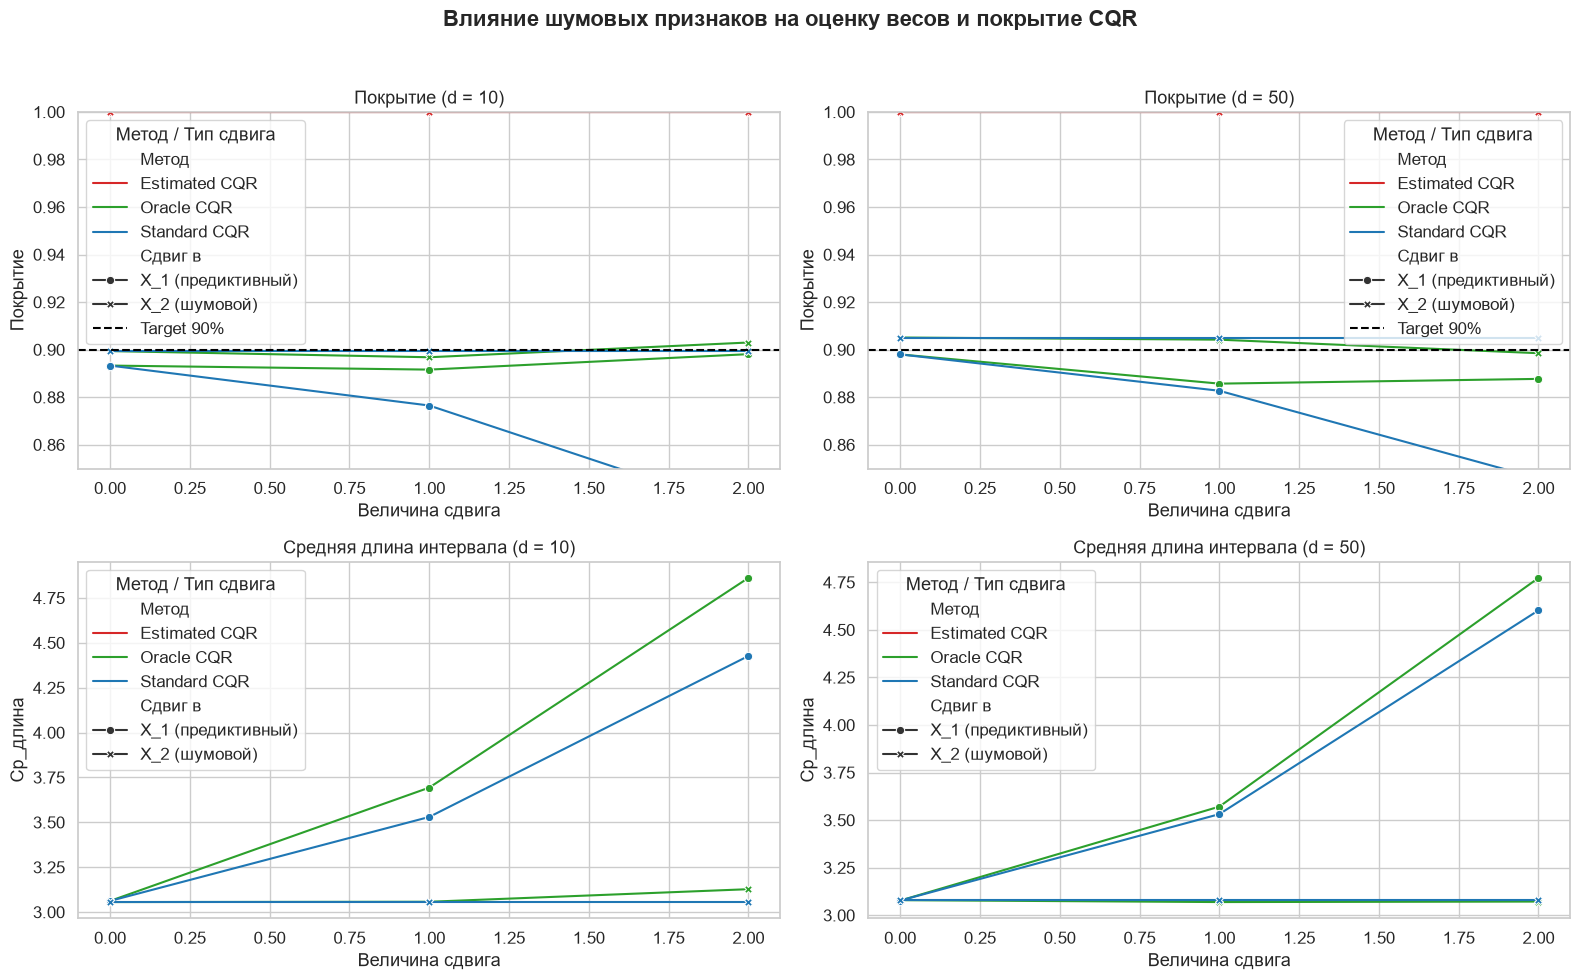


✅ Данные сохранены в cqr_nuisance_shift_experiment.xlsx


In [7]:
# Агрегация результатов (усредняем по trials)
df_agg = df_results.groupby(['d', 'Сдвиг в', 'Величина сдвига', 'Метод']).agg(
    Покрытие=('Покрытие', 'mean'),
    Ср_длина=('Ср. длина', 'mean'),
    Доля_inf=('Доля inf', 'mean')
).reset_index()

# ==========================================
# 📊 Вывод сводной таблицы в консоль
# ==========================================
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1200)
pd.set_option('display.float_format', '{:.3f}'.format)

print("\n" + "="*110)
print("СВОДНАЯ ТАБЛИЦА: Влияние шумовых признаков на оценку весов и покрытие CQR")
print("="*110)

# Форматируем таблицу для красивого вывода
df_table = df_agg.copy()
df_table['Покрытие'] = df_table['Покрытие'].map('{:.3f}'.format)
df_table['Ср_длина'] = df_table['Ср_длина'].map(lambda x: f"{x:.2f}" if not pd.isna(x) else "NaN")
df_table['Доля_inf'] = df_table['Доля_inf'].map('{:.3f}'.format)

print(df_table.to_markdown(index=False))
print("="*110)

# ==========================================
# 📈 Построение графиков
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Влияние шумовых признаков на оценку весов и покрытие CQR', fontsize=16, fontweight='bold')

palette = {'Standard CQR': '#1f77b4', 'Oracle CQR': '#2ca02c', 'Estimated CQR': '#d62728'}

for i, d in enumerate([10, 50]):
    df_d = df_agg[df_agg['d'] == d]
    
    # График покрытия
    ax = axes[0, i]
    sns.lineplot(data=df_d, x='Величина сдвига', y='Покрытие', hue='Метод', style='Сдвиг в', 
                 markers=True, dashes=False, palette=palette, ax=ax)
    ax.axhline(0.9, color='black', linestyle='--', label='Target 90%')
    ax.set_title(f'Покрытие (d = {d})')
    ax.set_ylim(0.85, 1.0)
    ax.legend(title='Метод / Тип сдвига')
    
    # График длины
    ax = axes[1, i]
    sns.lineplot(data=df_d, x='Величина сдвига', y='Ср_длина', hue='Метод', style='Сдвиг в', 
                 markers=True, dashes=False, palette=palette, ax=ax)
    ax.set_title(f'Средняя длина интервала (d = {d})')
    ax.legend(title='Метод / Тип сдвига')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ==========================================
# 💾 Сохранение в Excel
# ==========================================
excel_filename = "cqr_nuisance_shift_experiment.xlsx"
try:
    with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
        df_results.to_excel(writer, sheet_name='Raw_Results', index=False)
        df_agg.to_excel(writer, sheet_name='Aggregated_Results', index=False)
    print(f"\n✅ Данные сохранены в {excel_filename}")
except ImportError:
    print("\n❌ Установите openpyxl для сохранения в Excel: pip install openpyxl")

Что-то произошло с методом с неизвестным распределением (Estimated CQR), он почему-то улетает на бесконечность. У Oracle CQR доля покрытия растет, когда у CQR она падает при работе со средним X_1, с X_2 точность Oracle CQR немного падает, но точность CQR остается стабильно отличной (насколько это нормально?)